# OWMAS results demonstration

This notebook rebuilds the two main tables and three registered figures from the committed result files. It does not change the experiment, data, or registered settings.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'results').is_dir():
    ROOT = ROOT.parent
RESULTS = ROOT / 'results'
print(f'Reading committed results from: {RESULTS.resolve()}')

Reading committed results from: results


## Table 1. Full-sample performance

Returns, risk, and exposure are percentages. Sharpe and Sortino ratios are annualised.


In [2]:
performance = pd.read_csv(RESULTS / 'performance_metrics.csv', index_col='strategy')
table1 = performance.rename(columns={
    'cumulative_return': 'Cumulative return', 'cagr': 'CAGR',
    'sharpe': 'Sharpe', 'sortino': 'Sortino',
    'max_drawdown': 'Max drawdown', 'volatility': 'Volatility',
    'exposure': 'Exposure', 'trades': 'Trades',
})[['Cumulative return', 'CAGR', 'Sharpe', 'Sortino',
    'Max drawdown', 'Volatility', 'Exposure', 'Trades']]
table1

,Cumulative return,CAGR,Sharpe,Sortino,Max drawdown,Volatility,Exposure,Trades
strategy,,,,,,,,
OWMAS,274.26%,6.50%,0.458,0.627,-24.60%,11.45%,69.22%,109
SMA,216.92%,5.66%,0.383,0.516,-28.36%,11.71%,69.14%,105
WMA,265.81%,6.38%,0.459,0.627,-22.07%,11.12%,68.33%,133
EMA,456.22%,8.53%,0.627,0.863,-25.35%,11.37%,74.52%,73
BuyHold,741.02%,10.69%,0.539,0.758,-55.19%,19.05%,100.00%,1


## Table 2. Paired Sharpe-ratio tests

The 95% intervals include zero for all comparisons, so the registered results do not support a Sharpe improvement.


In [3]:
table2 = pd.read_csv(RESULTS / 'h1_sharpe_tests.csv').rename(columns={
    'comparison': 'Comparison', 'difference': 'Difference',
    'ci_low': '95% CI low', 'ci_high': '95% CI high',
    'p_value_two_sided': 'p-value', 'block_size': 'Block size',
})[['Comparison', 'Difference', '95% CI low', '95% CI high', 'p-value', 'Block size']]
table2.set_index('Comparison')

,Difference,95% CI low,95% CI high,p-value,Block size
Comparison,,,,,
OWMAS - SMA,0.0754,-0.0685,0.2192,0.2980,60
OWMAS - WMA,-0.0004,-0.1860,0.1853,0.9976,63
OWMAS - EMA,-0.1686,-0.3937,0.0565,0.1389,81
OWMAS - BuyHold,-0.0806,-0.5537,0.3925,0.7067,140


## Figure 1. Growth of one dollar


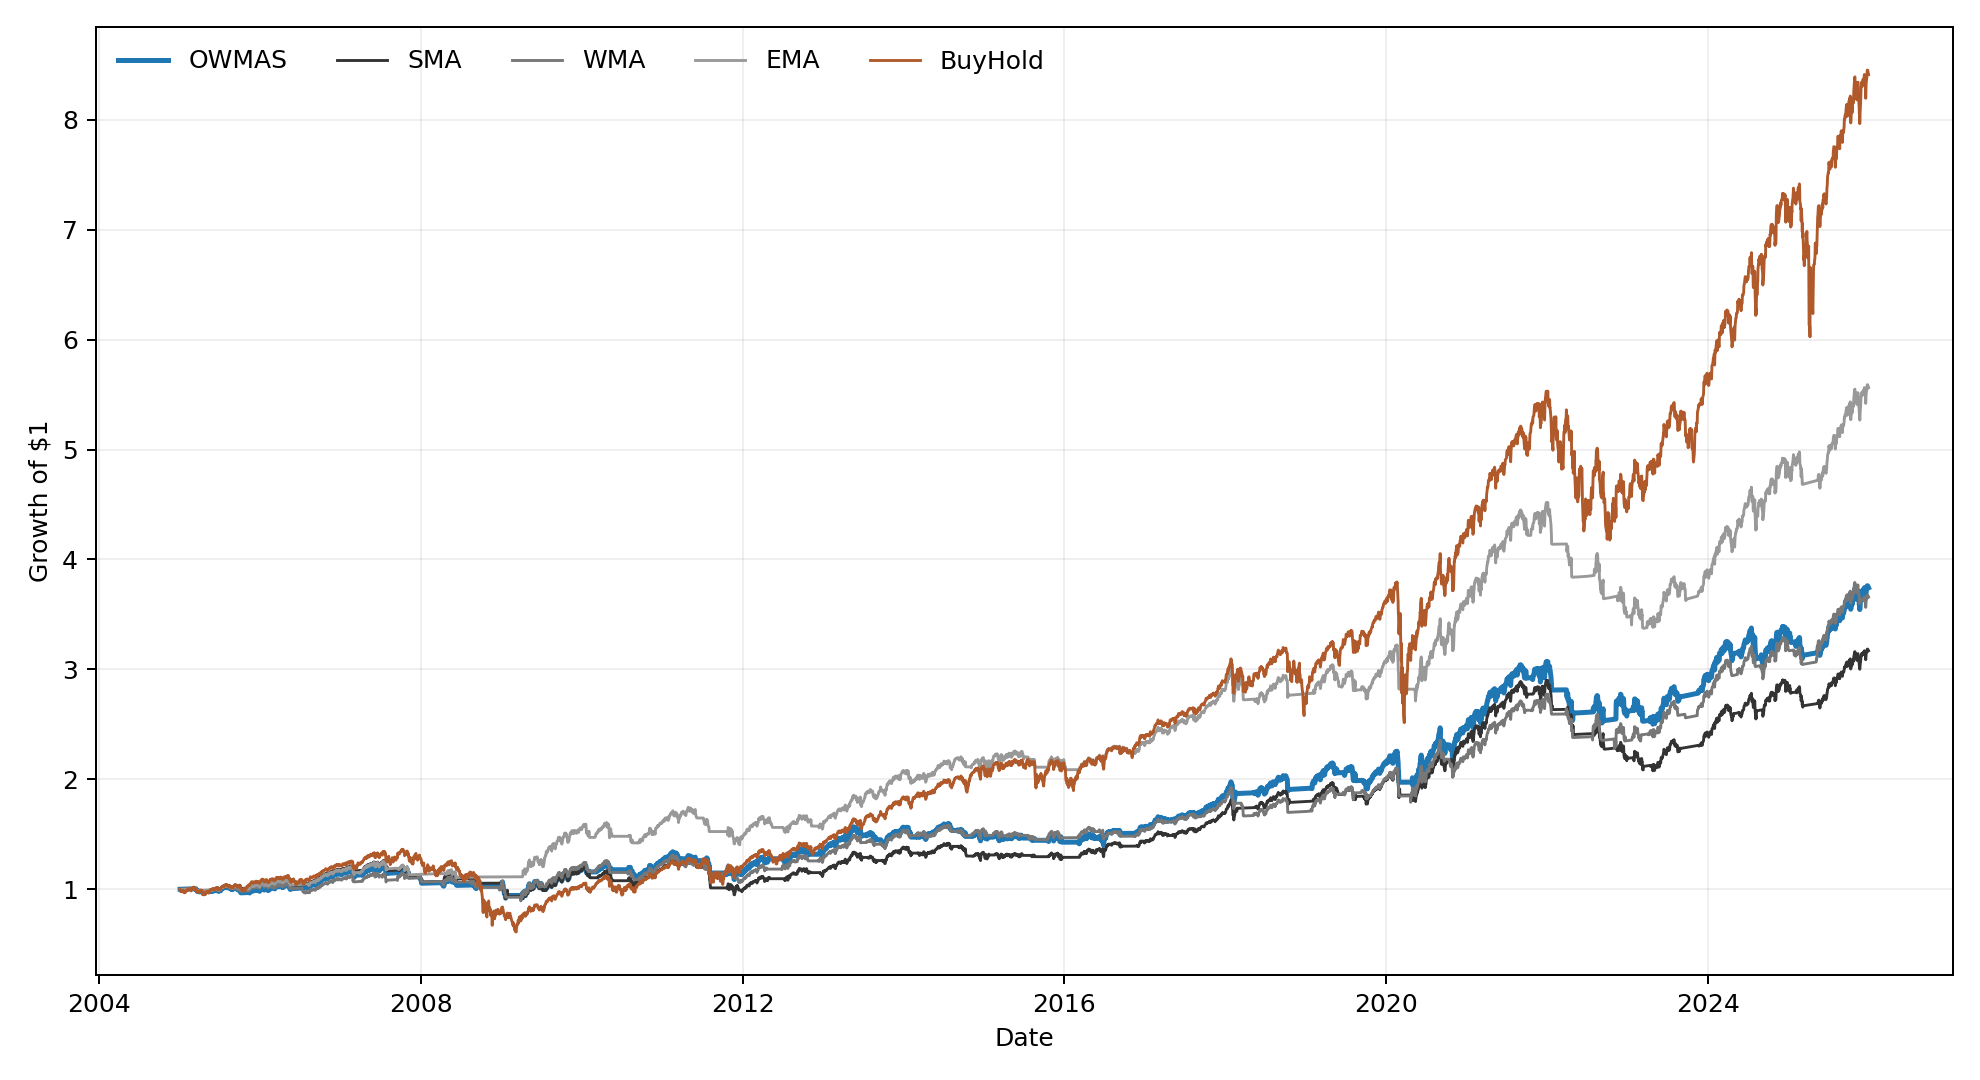

In [4]:
equity = pd.read_csv(RESULTS / 'equity_curves.csv', parse_dates=['date']).set_index('date')
ax = equity.plot(figsize=(11, 6), color=['#1f77b4', '#333333', '#777777', '#999999', '#b05a2b'])
ax.set_xlabel('Date'); ax.set_ylabel('Growth of $1'); ax.grid(True, alpha=0.2)
plt.tight_layout(); plt.show()

## Figure 2. Full-sample drawdowns


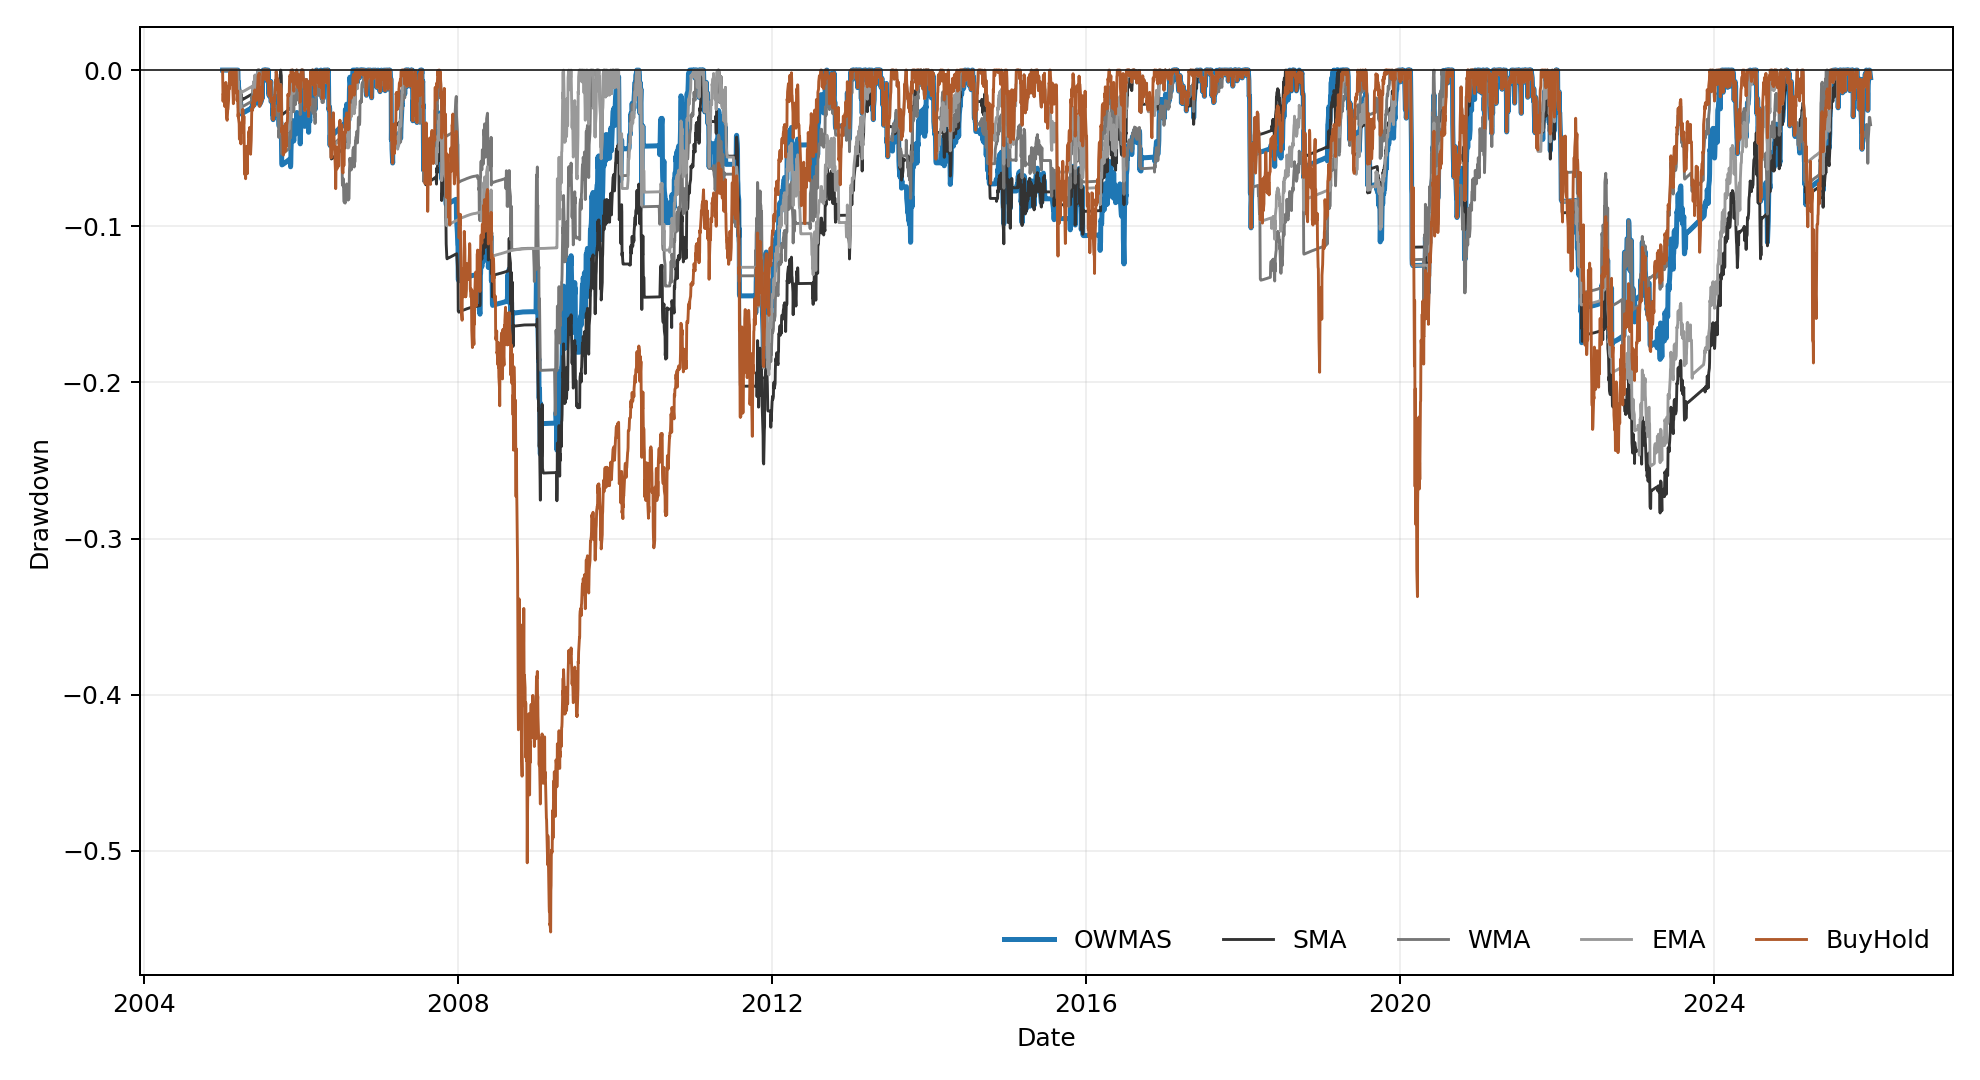

In [5]:
drawdowns = pd.read_csv(RESULTS / 'drawdowns.csv', parse_dates=['date']).set_index('date')
ax = drawdowns.plot(figsize=(11, 6), color=['#1f77b4', '#333333', '#777777', '#999999', '#b05a2b'])
ax.axhline(0.0, color='#222222', linewidth=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('Drawdown'); ax.grid(True, alpha=0.2)
plt.tight_layout(); plt.show()

## Figure 3. Rolling 252-day Sharpe ratios


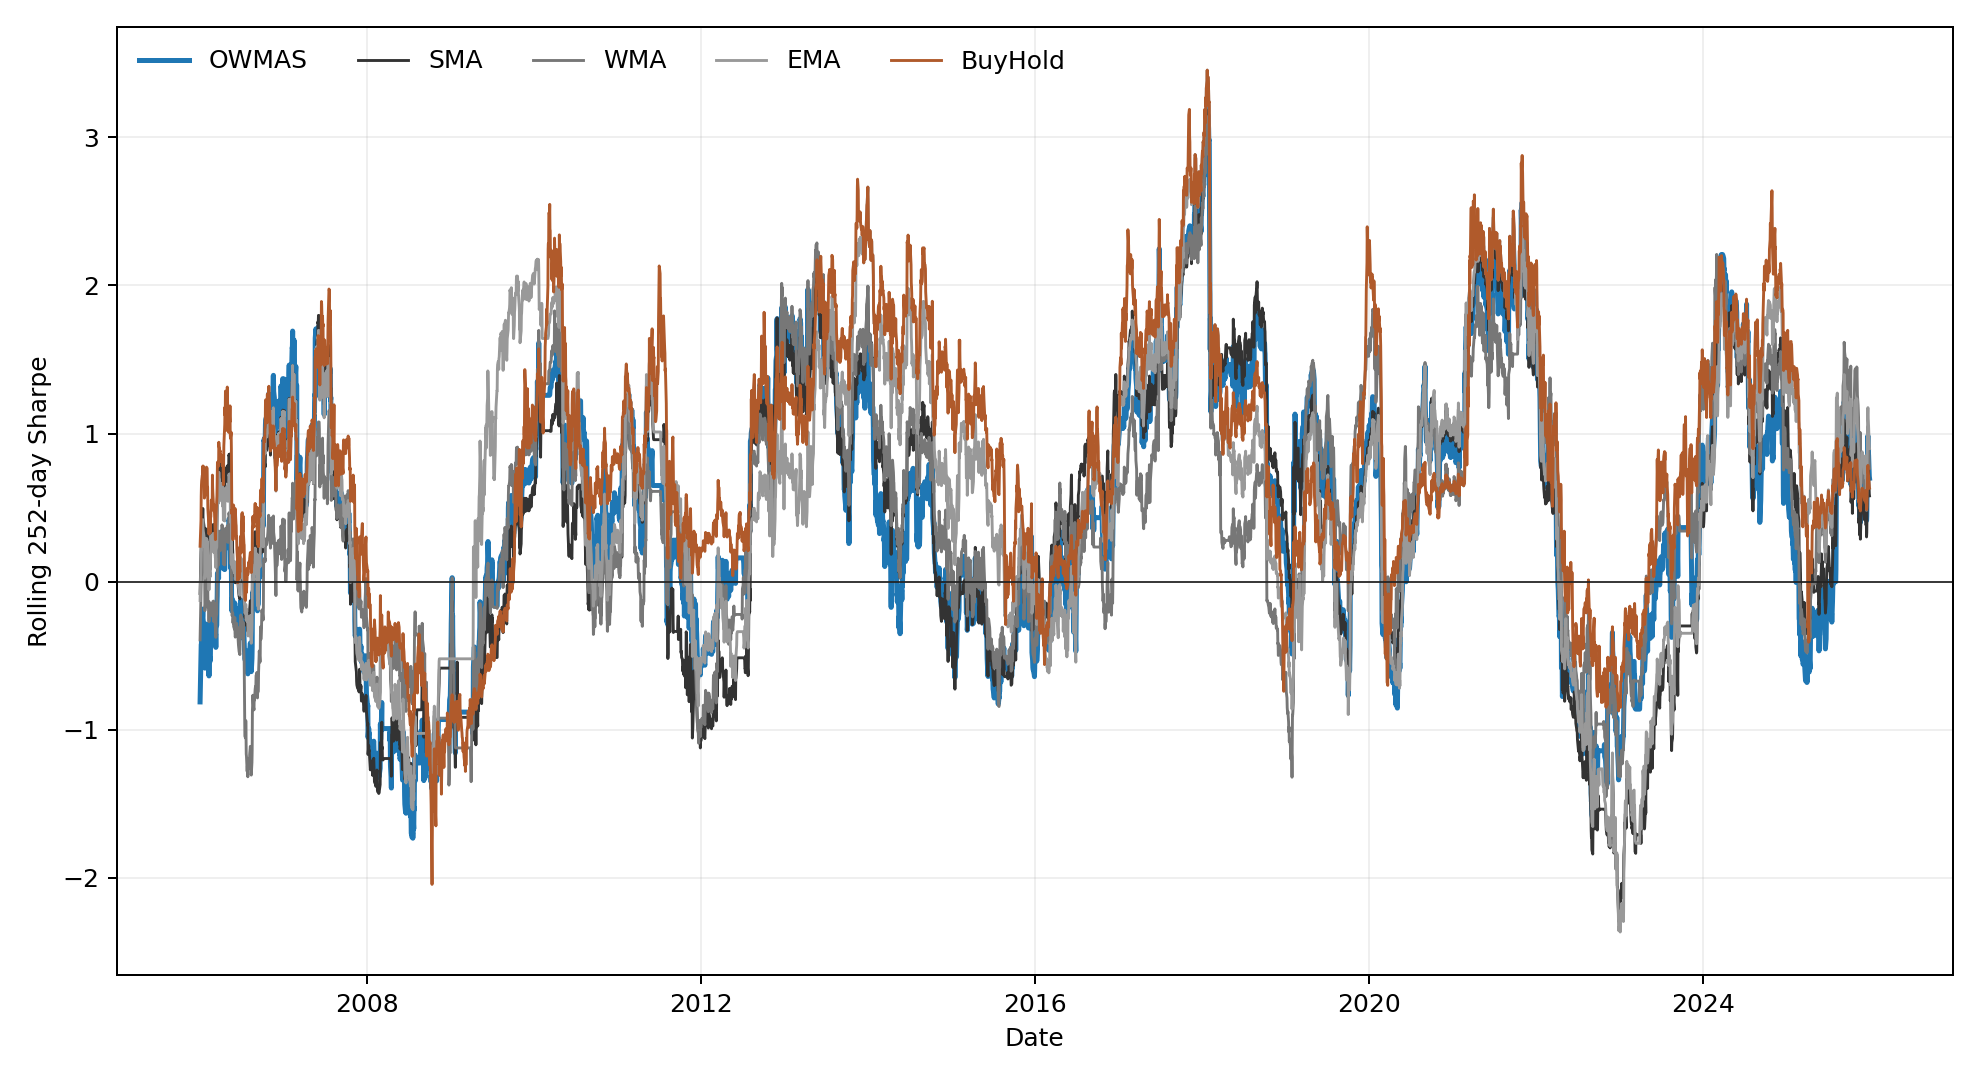

In [6]:
rolling = pd.read_csv(RESULTS / 'rolling_sharpe.csv', parse_dates=['date']).set_index('date')
ax = rolling.plot(figsize=(11, 6), color=['#1f77b4', '#333333', '#777777', '#999999', '#b05a2b'])
ax.axhline(0.0, color='#222222', linewidth=0.7)
ax.set_xlabel('Date'); ax.set_ylabel('Rolling 252-day Sharpe'); ax.grid(True, alpha=0.2)
plt.tight_layout(); plt.show()

## Reading the result

OWMAS had a higher full-sample Sharpe estimate than SMA, was effectively tied with WMA, and was below EMA. None of those differences was statistically significant at the 5% level. The main result is therefore a transparent null finding rather than evidence of consistent outperformance.
